# Laboratorio. Lezione 1
## Come «ragiona» un'intelligenza artificiale?

**Museo CTRL+Alt, Pavia · Università di Pavia**

---

In questa ora avete sentito dire che un modello linguistico **prevede la parola successiva**.

Adesso lo verificate voi. Useremo un modello vero, piccolo e italiano, che gira dentro questa pagina.

### Come si usa

- Ogni blocco si esegue premendo il tasto **▶** a sinistra della cella (oppure **Shift + Invio**).
- Le righe marcate con `# CAMBIA QUI` sono quelle su cui dovete sperimentare.
- **Non serve saper programmare.** Dovete solo cambiare le frasi fra virgolette.
- Se qualcosa si rompe: menu *Runtime* → *Riavvia sessione*, e si riparte dal Blocco 0.

---
## Blocco 0: Accendiamo il motore

Questa cella scarica il modello. Ci mette circa **un minuto** la prima volta.

Il modello si chiama `GroNLP/gpt2-small-italian`: ha circa **124 milioni di parametri**.
Per confronto, i modelli commerciali ne hanno centinaia di miliardi, circa **mille volte di più**.
È piccolo apposta: così gira sul vostro computer e fa errori abbastanza buffi da far capire il meccanismo.

In [1]:
# Esegui questa cella e aspetta che compaia "TUTTO PRONTO"
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM
import matplotlib.pyplot as plt

NOME_MODELLO = "GroNLP/gpt2-small-italian"

print("Scarico il modello, attendere...")
tokenizer = AutoTokenizer.from_pretrained(NOME_MODELLO)
model = AutoModelForCausalLM.from_pretrained(NOME_MODELLO)
model.eval()
tokenizer.pad_token = tokenizer.eos_token

n_parametri = sum(p.numel() for p in model.parameters())
print()
print("TUTTO PRONTO")
print(f"Parametri del modello: {n_parametri:,}")
print(f"Parole conosciute (vocabolario): {tokenizer.vocab_size:,}")

Scarico il modello, attendere...

TUTTO PRONTO
Parametri del modello: 108,883,200
Parole conosciute (vocabolario): 30,000


> **Nota importante.** Questo modello **non è un chatbot**: non risponde alle domande.
> Sa fare una cosa sola: **continuare un testo**.
>
> Quindi non gli scriveremo *«Di che colore è il cielo?»* ma *«Il cielo è di colore»*,
> e lui continuerà. È esattamente il mestiere di cui parlava la lezione, senza niente costruito sopra.

---
# Blocco 1: Le parole diventano numeri

**Collegamento:** slide *«Le parole diventano numeri»*

Il modello non legge lettere. Spezza il testo in **token** (pezzetti) e a ognuno dà un numero.

In [2]:
# CAMBIA QUI: scrivi la frase che vuoi
frase = "Ieri sono andato al mare e ho fatto un bagno"

token_id = tokenizer.encode(frase)
pezzi = [tokenizer.decode([t]) for t in token_id]

print(f"Frase:   {frase}")
print(f"Parole:  {len(frase.split())}")
print(f"Token:   {len(token_id)}")
print()
print("Come il modello la vede:")
print("  " + " | ".join(f"{p.strip()}" for p in pezzi))
print()
print("E i numeri corrispondenti:")
print("  " + " | ".join(str(t) for t in token_id))

Frase:   Ieri sono andato al mare e ho fatto un bagno
Parole:  10
Token:   11

Come il modello la vede:
  I | eri | sono | andato | al | mare | e | ho | fatto | un | bagno

E i numeri corrispondenti:
  41 | 401 | 465 | 6990 | 301 | 2877 | 278 | 1048 | 857 | 297 | 9864


### Provate voi

Rimettete la cella qui sopra con una frase diversa e guardate cosa succede. Suggerimenti:

| Prova a scrivere | Cosa dovreste notare |
|---|---|
| Il vostro nome | I nomi comuni restano interi, quelli rari si spezzano in 3-4 pezzi |
| `straordinariamente` | Una parola sola diventa parecchi token |
| `ciao 🍕🚀` | Un emoji può valere più token di una parola |
| Una frase in inglese | Questo modello è italiano: l'inglese lo spezzetta male |

La cella qui sotto fa il confronto in automatico.

In [5]:
# CAMBIA QUI: metti le parole che vuoi confrontare
parole = ["Marco", "Brando", "casa", "straordinariamente", "pizza", "Leonforte", "computer"]

print(f"{'parola':<25} {'token':>6}   come viene spezzata")
print("-" * 70)
for p in parole:
    ids = tokenizer.encode(p)
    pezzi = [tokenizer.decode([t]).strip() for t in ids]
    print(f"{p:<25} {len(ids):>6}   {' + '.join(pezzi)}")

parola                     token   come viene spezzata
----------------------------------------------------------------------
Marco                          1   Marco
Brando                         2   B + rando
casa                           1   casa
straordinariamente             3   stra + ordina + riamente
pizza                          2   pi + zza
Leonforte                      3   Le + on + forte
computer                       2   com + puter


> **Perché conta?** I servizi a pagamento si pagano **a token**, non a parola.
> E un modello che spezza male la vostra lingua la capisce peggio e costa di più.

---
# Blocco 2: La lista delle probabilità

**Collegamento:** slide *«Esce la lista delle probabilità»*

Questo è il cuore di tutto. Diamo al modello un inizio di frase e guardiamo
**cosa produce davvero**: non una parola, ma un voto per ognuna delle 30.000 parole che conosce.

Qui sotto vediamo le 10 messe meglio.

"Ieri sono andato al mare e ho fatto un ___"

  '                   10.9%  #####
  giro                 9.3%  ####
  viaggio              5.8%  ##
  po                   4.7%  ##
  salto                4.1%  ##
  bel                  3.3%  #
  paio                 2.3%  #
  bagno                2.1%  #
  sacco                2.0%  #
  volo                 1.2%  

Queste 10 parole insieme fanno il 45.7% del totale.
Il restante si distribuisce sulle altre 29,990 parole.


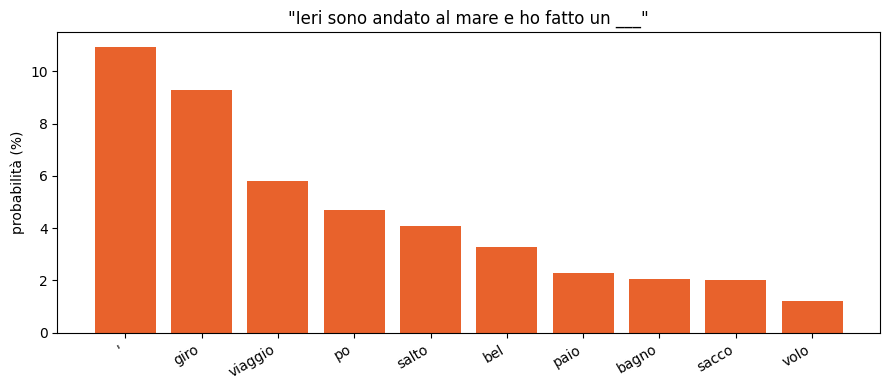

In [6]:
# CAMBIA QUI: scrivi un inizio di frase (senza punto finale)
inizio = "Ieri sono andato al mare e ho fatto un"

QUANTE = 10

ids = tokenizer.encode(inizio, return_tensors="pt")
with torch.no_grad():
    logits = model(ids).logits[0, -1, :]     # punteggi grezzi
probabilita = F.softmax(logits, dim=-1)      # trasformati in percentuali

top = torch.topk(probabilita, QUANTE)
parole = [tokenizer.decode([i]).strip() or "(spazio)" for i in top.indices]
valori = [v.item() * 100 for v in top.values]

print(f'"{inizio} ___"')
print()
for p, v in zip(parole, valori):
    print(f"  {p:<18} {v:5.1f}%  {'#' * int(v / 2)}")
print()
print(f"Queste 10 parole insieme fanno il {sum(valori):.1f}% del totale.")
print(f"Il restante si distribuisce sulle altre {tokenizer.vocab_size - QUANTE:,} parole.")

plt.figure(figsize=(9, 4))
plt.bar(parole, valori, color="#E8622C")
plt.ylabel("probabilità (%)")
plt.title(f'"{inizio} ___"')
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Provate voi

- `"Il gatto è un animale"` → vedrete aggettivi
- `"Chi dorme non piglia"` → una sola parola dominerà (è un proverbio: facile da indovinare)
- `"La capitale della Francia è"` → funziona?
- `"Oggi mi sento molto"` → tante possibilità, tutte con percentuali basse

**Domanda da farsi:** quando la prima parola ha il 90% e quando invece ha il 12%?
Che differenza c'è fra le due frasi?

---
# Blocco 3: Prendere sempre la prima, oppure tirare il dado

**Collegamento:** slide *«Scelta 1 / Scelta 2»* (superiori) · *«E adesso come sceglie?»* (medie)

Adesso il confronto decisivo. Facciamo scrivere al modello la stessa frase **cinque volte**,
nei due modi diversi.

In [7]:
# CAMBIA QUI
inizio = "Il gatto è un animale"
QUANTE_PAROLE = 15

ids = tokenizer.encode(inizio, return_tensors="pt")

print("=" * 65)
print("MODO 1: prende SEMPRE la parola più probabile (greedy)")
print("=" * 65)
for giro in range(5):
    with torch.no_grad():
        out = model.generate(ids, max_new_tokens=QUANTE_PAROLE,
                             do_sample=False,
                             pad_token_id=tokenizer.eos_token_id)
    print(f"  {giro + 1}. {tokenizer.decode(out[0], skip_special_tokens=True)}")

print()
print("=" * 65)
print("MODO 2: tira il dado truccato (campionamento)")
print("=" * 65)
for giro in range(5):
    with torch.no_grad():
        out = model.generate(ids, max_new_tokens=QUANTE_PAROLE,
                             do_sample=True, temperature=1.0, top_k=0,
                             pad_token_id=tokenizer.eos_token_id)
    print(f"  {giro + 1}. {tokenizer.decode(out[0], skip_special_tokens=True)}")

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


MODO 1 — prende SEMPRE la parola più probabile (greedy)
  1. Il gatto è un animale che vive in un ambiente di natura, ma che vive in un ambiente di
  2. Il gatto è un animale che vive in un ambiente di natura, ma che vive in un ambiente di
  3. Il gatto è un animale che vive in un ambiente di natura, ma che vive in un ambiente di
  4. Il gatto è un animale che vive in un ambiente di natura, ma che vive in un ambiente di
  5. Il gatto è un animale che vive in un ambiente di natura, ma che vive in un ambiente di

MODO 2 — tira il dado truccato (campionamento)
  1. Il gatto è un animale crudele non solo con i sensi vestiti, ma anche a coprire qualsiasiocculto
  2. Il gatto è un animale di possessione. Sebbene molto insolito nel suo genere debole, è molto
  3. Il gatto è un animale onnivoro, non sopporta il cibo tranne in rari casi, ma è inoltre
  4. Il gatto è un animale nuovo: più aggressivi, più angusta. A torto si rifiuta
  5. Il gatto è un animale che si nutre di uova. Durante le prim

### Cosa avete visto

Il **Modo 1** ha stampato cinque righe **identiche**. Sempre. Anche se rieseguite fra un'ora.
Spesso si incastra anche in ripetizioni (*«molto molto molto»*).

Il **Modo 2** ha stampato cinque righe **tutte diverse**.

> **Ecco la risposta alla domanda che vi siete fatti tutti:**
> ChatGPT usa il Modo 2. Per questo, se rifate la stessa domanda, la risposta cambia.

---
# Blocco 4. La manopola: la temperatura

**Collegamento:** slide *«Scelta 2, il campionamento»*

La **temperatura** decide quanto è truccato il dado.

- **bassa** (0.2) → la parola più probabile domina. Testo prevedibile e noioso.
- **media** (0.8-1.0) → equilibrio. È più o meno dove stanno i chatbot veri.
- **alta** (1.8+) → tutte le parole diventano quasi uguali. Il modello delira.

In [18]:
# CAMBIA QUI
inizio = "La pizza margherita è"
QUANTE_PAROLE = 25

# CAMBIA QUI: prova altri valori, per esempio 0.1 oppure 3.0
temperature = [0.2, 0.7, 1.0, 1.5, 2.0]

ids = tokenizer.encode(inizio, return_tensors="pt")

for t in temperature:
    with torch.no_grad():
        out = model.generate(ids, max_new_tokens=QUANTE_PAROLE,
                             do_sample=True, temperature=t, top_k=0,
                             pad_token_id=tokenizer.eos_token_id)
    testo = tokenizer.decode(out[0], skip_special_tokens=True)
    print(f"--- temperatura {t}")
    print(f"    {testo}")
    print()

--- temperatura 0.2
    La pizza margherita è un piatto tipico della cucina toscana, che si caratterizza per la presenza di ingredienti tipici della cucina toscana.

Il piatto è

--- temperatura 0.7
    La pizza margherita è un piatto tipico dei locali della zona. La pizza è un dolce da pane dolce dolce, molto ricercato nella zona.



--- temperatura 1.0
    La pizza margherita è come piercing (ANSA) - CASTEL SAN DOZZO DI BRANCOLO A BARCERE, 3 MAG

--- temperatura 1.5
    La pizza margherita è quanto aspetti que ogni?avventore h “anellaf&emo(^ Frayan^3 pan chiusordine |

--- temperatura 2.0
    La pizza margherita è recuperato batter fino complicaportae rischi ultimi ultra-artigianato felice kit 04 ampi locali comuni AccNoi vinedi FeditCircy



### Provate voi

Fate girare la cella **più volte con la stessa temperatura**: a 0.2 le frasi si somigliano molto,
a 2.0 sono sempre completamente diverse.

**Domanda:** secondo voi, per scrivere una mail formale conviene una temperatura alta o bassa?
E per inventare una storia?

---
# Blocco 5: Una parola alla volta

**Collegamento:** slide *«E poi ricomincia da capo»*

Qui vedete il ciclo dall'interno. Ogni volta che eseguite la cella, il modello aggiunge
**una sola parola**, e poi rifà tutto il giro da capo sul testo allungato.

In [39]:
# CAMBIA QUI (solo la prima volta): il punto di partenza
PARTENZA = "I gatti mangiano"

# Prepara il testo: riparte da PARTENZA se non esiste ancora
if "testo" not in globals():
    testo = PARTENZA

ids = tokenizer.encode(testo, return_tensors="pt")
with torch.no_grad():
    logits = model(ids).logits[0, -1, :]
probabilita = F.softmax(logits, dim=-1)

# Le 5 candidate, prima di scegliere
top = torch.topk(probabilita, 5)
resto = (1 - top.values.sum().item()) * 100
print(f'Testo finora:  "{testo}"')
print()
print(f"Il modello valuta tutte le {len(probabilita):,} parole che conosce.")
print("Queste sono le 5 piu' probabili:")
for i, v in zip(top.indices, top.values):
    print(f"   {tokenizer.decode([i]).strip() or '(spazio)':<16} {v.item() * 100:5.1f}%")
print(f"   {'... tutte le altre':<16} {resto:5.1f}%   <-- puo' pescare anche qui")

# Estrae una parola secondo le probabilità (il dado truccato)
scelto = torch.multinomial(probabilita, num_samples=1)
parola = tokenizer.decode(scelto)
testo = testo + parola

print()
print(f"Ha estratto:   '{parola.strip()}'")
print(f"Nuovo testo:   \"{testo}\"")
print()
print(">>> Esegui di nuovo questa cella per la parola successiva.")

Testo finora:  "I gatti mangiano veramente dolce. Del resto, gliela tutti Una febbre dilatata a Bagdad ci ha moltipli"

Il modello valuta tutte le 30,001 parole che conosce.
Queste sono le 5 piu' probabili:
   cato              98.1%
   cata               1.5%
   cati               0.1%
   c                  0.0%
   cano               0.0%
   ... tutte le altre   0.1%   <-- puo' pescare anche qui

Ha estratto:   'cato'
Nuovo testo:   "I gatti mangiano veramente dolce. Del resto, gliela tutti Una febbre dilatata a Bagdad ci ha moltiplicato"

>>> Esegui di nuovo questa cella per la parola successiva.


### Come si usa

1. Eseguite la cella. Guardate le 5 candidate e quale è stata estratta.
2. **Rieseguite la stessa cella.** Il testo si allunga di una parola.
3. Ripetete 10-15 volte e guardate la frase crescere.

> Notate che le 5 candidate **cambiano a ogni giro**: dipendono da tutto quello
> che è stato scritto fino a quel momento. Il modello non ha un piano:
> quando sceglie la decima parola non sa ancora come finirà la frase.

**Per ricominciare da un'altra frase:** eseguite la cella qui sotto, poi tornate sopra.

In [20]:
# Azzera il Blocco 5
if "testo" in globals():
    del testo
print("Azzerato. Torna alla cella del Blocco 5 e cambia PARTENZA.")

Azzerato. Torna alla cella del Blocco 5 e cambia PARTENZA.


---
# Blocco 6: Quando se le inventa

**Collegamento:** slide *«Quindi non capisce. E si vede.»*

Il modello non ha un campanello che suona quando non sa una cosa.
Per lui scrivere una cosa vera e inventarsela sono **la stessa identica operazione**:
mettere in fila parole probabili.

Qui sotto gli diamo da continuare una frase su una persona **che non esiste**.

In [ ]:
# CAMBIA QUI: inventa un personaggio e un fatto che non esistono
inizi_falsi = [
    "Il professor Aldo Barbieri, inventore del tostapane solare, è nato a",
    "La battaglia di Monteverde del 1673 fu combattuta tra",
    "Il romanzo «Il giardino di vetro» racconta la storia di",
]

for inizio in inizi_falsi:
    ids = tokenizer.encode(inizio, return_tensors="pt")
    with torch.no_grad():
        out = model.generate(ids, max_new_tokens=30,
                             do_sample=True, temperature=0.8, top_k=50,
                             pad_token_id=tokenizer.eos_token_id)
    print("-" * 70)
    print(tokenizer.decode(out[0], skip_special_tokens=True))
    print()

### Cosa avete visto

Il modello ha continuato **senza esitare**. Non ha scritto «non lo so», non ha messo un dubbio.
Ha prodotto parole plausibili, come fa sempre.

Si chiamano **allucinazioni**.

> Per il modello ogni domanda è un'interrogazione: conviene inventare qualcosa
> piuttosto che ammettere di non aver studiato.

**Attenzione:** i chatbot veri sono molto più bravi di questo modellino e sbagliano molto meno.
Ma il meccanismo è esattamente lo stesso, e succede ancora. **Quello che vi dicono va sempre verificato.**

---
# Blocco 7: La softmax a mano

> ### Solo per le scuole superiori
> Questo blocco rifà a mano il conto della slide *«Da punteggi a probabilità»*.
> Se non avete visto quella slide, potete saltarlo.

**Collegamento:** slide *«Da punteggi a probabilità: la softmax»*

La rete non produce percentuali: produce **logits**, punteggi grezzi che possono anche essere negativi.
La softmax li trasforma in probabilità che sommano a 1:

$$y_i = \frac{e^{u_i}}{\sum_{j} e^{u_j}}$$

Verifichiamo prima sui numeri della slide, poi su quelli veri del modello.

In [40]:
import numpy as np

# I numeri esatti della slide
parole  = ["bagno", "tuffo", "giro", "castello"]
logits_slide = np.array([1.2, 0.9, 0.1, -0.5])

print("PASSO 1: esponenziale di ogni logit (rende tutto positivo)")
esponenziali = np.exp(logits_slide)
for p, u, e in zip(parole, logits_slide, esponenziali):
    print(f"   {p:<10} exp({u:>5.1f}) = {e:.4f}")

print()
print("PASSO 2: somma di tutti gli esponenziali")
somma = esponenziali.sum()
print(f"   somma = {somma:.4f}")

print()
print("PASSO 3: ognuno diviso la somma")
probabilita_a_mano = esponenziali / somma
for p, y in zip(parole, probabilita_a_mano):
    print(f"   {p:<10} {y:.4f}  ({y * 100:.0f}%)")

print()
print(f"VERIFICA: la somma fa {probabilita_a_mano.sum():.4f}  (deve fare 1)")

PASSO 1 — esponenziale di ogni logit (rende tutto positivo)
   bagno      exp(  1.2) = 3.3201
   tuffo      exp(  0.9) = 2.4596
   giro       exp(  0.1) = 1.1052
   castello   exp( -0.5) = 0.6065

PASSO 2 — somma di tutti gli esponenziali
   somma = 7.4914

PASSO 3 — ognuno diviso la somma
   bagno      0.4432  (44%)
   tuffo      0.3283  (33%)
   giro       0.1475  (15%)
   castello   0.0810  (8%)

VERIFICA — la somma fa 1.0000  (deve fare 1)


### Ora sui numeri veri

Prendiamo i logits che il modello produce davvero e verifichiamo che la nostra softmax
scritta a mano dia lo stesso risultato di quella di PyTorch.

In [41]:
inizio = "Ieri sono andato al mare e ho fatto un"

ids = tokenizer.encode(inizio, return_tensors="pt")
with torch.no_grad():
    logits_veri = model(ids).logits[0, -1, :]

# Le 5 candidate migliori
top = torch.topk(logits_veri, 5)

print(f'"{inizio} ___"')
print()
print(f"{'parola':<16} {'logit':>9} {'softmax a mano':>16} {'softmax PyTorch':>17}")
print("-" * 62)

# softmax a mano, su TUTTO il vocabolario (come fa il modello)
u = logits_veri.numpy()
mia_softmax = np.exp(u - u.max()) / np.exp(u - u.max()).sum()   # -max = stabilità numerica
sua_softmax = F.softmax(logits_veri, dim=-1).numpy()

for idx in top.indices:
    i = idx.item()
    parola = tokenizer.decode([i]).strip() or "(spazio)"
    print(f"{parola:<16} {u[i]:>9.3f} {mia_softmax[i]:>16.6f} {sua_softmax[i]:>17.6f}")

print()
print(f"Differenza massima fra le due: {np.abs(mia_softmax - sua_softmax).max():.2e}")
print("Sono la stessa cosa. Il modello non fa niente di magico: fa questo conto.")

"Ieri sono andato al mare e ho fatto un ___"

parola               logit   softmax a mano   softmax PyTorch
--------------------------------------------------------------
'                   55.314         0.109409          0.109409
giro                55.151         0.092867          0.092867
viaggio             54.683         0.058165          0.058165
po                  54.465         0.046789          0.046789
salto               54.331         0.040941          0.040941

Differenza massima fra le due: 1.49e-07
Sono la stessa cosa. Il modello non fa niente di magico: fa questo conto.


> **Perché `- u.max()`?** Gli esponenziali diventano enormi in fretta e il computer va in overflow.
> Sottrarre il massimo prima di fare `exp` non cambia il risultato (si semplifica
> fra numeratore e denominatore) ma tiene i numeri in un intervallo gestibile.
> È un trucco standard, lo usano tutte le librerie.

### Esercizio

Provate a dividere i logits per un numero prima della softmax:

```python
T = 0.5                  # prova 0.1, 0.5, 1.0, 2.0
p = F.softmax(logits_veri / T, dim=-1)
```

Guardate come cambiano le probabilità. **Quel numero `T` è la temperatura del Blocco 4.**

---
# Riepilogo

Oggi avete verificato con le vostre mani che:

1. il testo viene spezzato in **token**, e ogni token ha un numero;
2. il modello non produce una parola, produce una **lista di probabilità** su tutto il vocabolario;
3. se prende sempre la più probabile (**greedy**), la risposta è sempre identica e noiosa;
4. se **tira a sorte** secondo le probabilità, ogni risposta è diversa, ed è così che funzionano i chatbot veri;
5. scrive **una parola alla volta**, senza sapere come finirà;
6. quando non sa una cosa, **se la inventa** con la stessa sicurezza di quando la sa.

> ## Non c'è un cervellino dentro la scatola.
> C'è una macchina che indovina la parola successiva, e lo fa molto bene.

---

### La prossima volta

Il modello segue il testo che legge. Prende per buono tutto quello che gli arriva.

**E se qualcuno nascondesse delle istruzioni dentro quel testo?**

→ *Lezione 2. Ingannare l'IA: i messaggi nascosti*